In [1]:
!pip install torchvision adabelief-pytorch==0.2.0 lion-pytorch -q


In [2]:
pip install kaggle torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
# =============================================================
# INSTALLATION, IMPORTS, AND GLOBAL CONFIGURATION
# =============================================================

# Install all required packages including specialized optimizers and monitoring tools
!pip install scikit-learn thop pynvml matplotlib seaborn tqdm torchinfo -q

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os
import seaborn as sns
import pynvml
import torch.nn.functional as F
import warnings
from collections import Counter, deque
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)



/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [4]:
import os
import shutil
from getpass import getpass

kaggle_path = input("Upload the kaggle.json: ")
dest_path = os.path.expanduser('~/.kaggle/kaggle.json')
os.makedirs(os.path.dirname(dest_path), exist_ok=True)
shutil.copy(kaggle_path, dest_path)
os.chmod(dest_path, 0o600)
print("✓ Kaggle configured")


✓ Kaggle configured


In [5]:
NUM_CLASSES = 11
NUM_EPOCHS  = 80
BATCH_SIZE  = 64
IMG_SIZE    = 96
device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters used in all experiments (no per-optimizer tuning).
# SGD: He et al. (2016) | Adam/Adamax: Kingma & Ba (2015) | AdamW: Loshchilov & Hutter (2019)
# RAdam: Liu et al. (2020) | AMSGrad: Reddi et al. (2018) | AdaBelief: Zhuang et al. (2020)
# Lion: Chen et al. (2023) | RMSprop: Tieleman & Hinton (2012)
HYPERPARAMS = {
    'SGD':       {'lr': 0.01,  'momentum': 0.9, 'weight_decay': 0},
    'RMSprop':   {'lr': 1e-3, 'alpha': 0.99, 'eps': 1e-8},
    'Adam':      {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AdamW':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0.01},
    'RAdam':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AMSGrad':   {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0, 'amsgrad': True},
    'Adamax':    {'lr': 2e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0},
    'AdaBelief': {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0,
                  'weight_decouple': False, 'rectify': False},
    'Lion':      {'lr': 1e-4, 'betas': (0.9, 0.99), 'weight_decay': 0.1},
    'AdaHarmon': {'lr': 1e-3, 'betas': (0.9, 0.999, 0.9), 'eps': (1e-8, 1e-6),
                  'lambda_s': 1.0, 'soft_decay': 0.5, 'tau': 0.1, 'amsgrad': False},
}

OPTIMIZERS_TO_RUN = ["Adam", "AdamW", "RAdam", "AdaHarmon", "RMSprop", "SGD", "AdaBelief", "Lion", "AMSGrad", "Adamax"]

print(f"✓ Configuration set. Device: {device}")
print(f"  NUM_CLASSES={NUM_CLASSES} | IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE} | NUM_EPOCHS={NUM_EPOCHS}")


✓ Configuration set. Device: cuda | PyTorch Version: 2.10.0
  NUM_CLASSES=11 | IMG_SIZE=96 | BATCH_SIZE=64 | NUM_EPOCHS=80


In [6]:
# =============================================================
# DATASET CONFIGURATION - Naturalize 2K-PBC (11 Classes)
# =============================================================
import os
import shutil
import zipfile

dataset_path = '/content/naturalize_pbc'
full_data_dir = os.path.join(dataset_path, 'full_dataset')
os.makedirs(dataset_path, exist_ok=True)

# ─── 1. DOWNLOAD FROM KAGGLE ───
print("Downloading Naturalize 2K-PBC dataset...")
os.system(f"kaggle datasets download -d mohamadabouali1/blood-cells-dataset-11-classes-26534-images -p {dataset_path} --unzip")

# ─── 2. THE DATASET IS ALREADY STRUCTURED ───
print("Dataset downloaded and extracted.")

import os

dataset_path = '/content/naturalize_pbc'
base_path = os.path.join(dataset_path, 'Naturalize 2K-PBC Dataset')

expected_folders = ['Train', 'Test', 'Validate']
print("Verifying...")
for folder in expected_folders:
    folder_path = os.path.join(base_path, folder)
    if os.path.exists(folder_path):
        num_classes = len([d for d in os.listdir(folder_path) if os.path.isdir(os.path.join(folder_path, d))])
        print(f"  ✓ Found '{folder}' with {num_classes} class subfolders.")
    else:
        print(f"  ✗ Warning: '{folder}' not found in {base_path}")



Dataset downloaded and extracted.
Verifying...
  ✓ Found 'Train' with 11 class subfolders.
  ✓ Found 'Test' with 11 class subfolders.
  ✓ Found 'Validate' with 11 class subfolders.



✓ Total images in 'Train': 21234

Class Distribution:
  Class                N       %
  -----------------------------------
  MMY               2407   11.3%  █████
  MO                1080    5.1%  ██
  LY                 962    4.5%  ██
  PLT               1744    8.2%  ████
  BA                 899    4.2%  ██
  SNE               2896   13.6%  ██████
  MY                2508   11.8%  █████
  EO                2351   11.1%  █████
  BNE               2897   13.6%  ██████
  ERB               1081    5.1%  ██
  PMY               2409   11.3%  █████


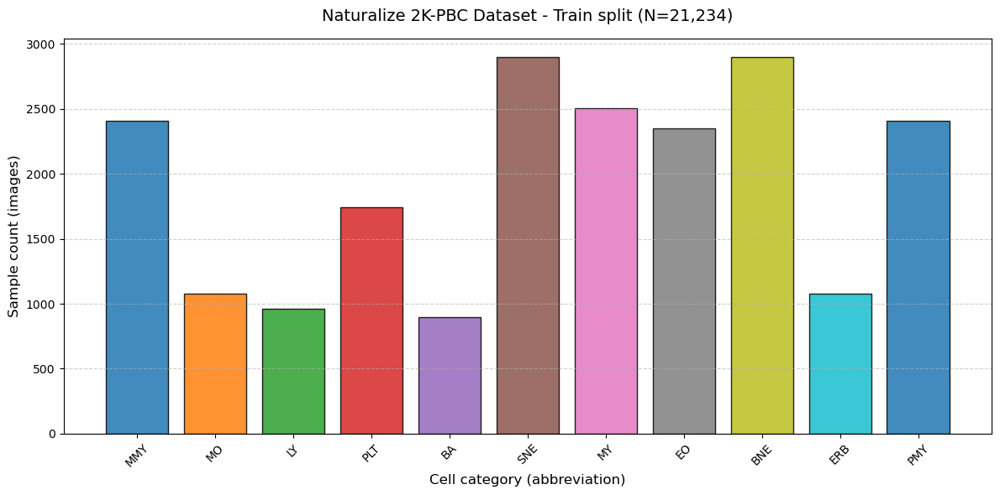


Verification completed.


In [7]:
# =============================================================
# DATASET VERIFICATION - NATURALIZE 2K-PBC CLASS DISTRIBUTION
# =============================================================
import os
import matplotlib.pyplot as plt

# Root directory of the dataset (after download)
dataset_root = '/content/naturalize_pbc/Naturalize 2K-PBC Dataset'

# Choose the split to analyze: 'Train', 'Validate', or 'Test'
target_split = 'Train'   # Change to 'Validate' or 'Test' as needed
base_dir = os.path.join(dataset_root, target_split)

VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png')

# Check if the folder exists
if not os.path.exists(base_dir):
    raise FileNotFoundError(f"Folder {base_dir} does not exist. Please verify the path.")

# Automatically detect class folders
categories = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]

data_summary = []
for category in categories:
    path = os.path.join(base_dir, category)
    n = len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTENSIONS)])
    data_summary.append((category, n))

total_n = sum(count for _, count in data_summary)
print(f"✓ Total images in '{target_split}': {total_n}")
print(f"\nClass Distribution:")
print(f"  {'Class':<15} {'N':>6} {'%':>7}")
print(f"  {'-'*35}")
for code, n in data_summary:
    pct = (n / total_n) * 100
    bar = '█' * int(pct / 2)
    print(f"  {code:<15} {n:>6} {pct:>6.1f}%  {bar}")

# Bar chart
plt.figure(figsize=(12, 6))
codes  = [item[0] for item in data_summary]
counts = [item[1] for item in data_summary]
plt.bar(codes, counts, color=plt.cm.tab10.colors[:len(codes)], edgecolor='black', alpha=0.85)
plt.title(f"Naturalize 2K-PBC Dataset - {target_split} split (N={total_n:,})", fontsize=14, pad=15)
plt.xlabel("Cell category (abbreviation)", fontsize=12)
plt.ylabel("Sample count (images)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nVerification completed.")


In [8]:
# =============================================================
# PROPOSED OPTIMIZER
# =============================================================
import torch
from torch.optim import Optimizer


class AdaHarmon(Optimizer):
    r"""
    AdaHarmon: Adaptive Harmonic Optimizer

    Algorithm:
    ----------
    Let g_t be the gradient at step t.

    1. Sign consistency tracker:
       s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)

    2. Adaptive momentum:
       β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
       μ_t    = μ_{t-1} · β₁^(t)           ← exact accumulated product

    3. First moment (gradient EMA):
       m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
       m̂_t = m_t / (1 - μ_t)               ← exact bias correction

    4. Second moment (L2 norm):
       v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
       v̂_t = v_t / (1 - β₂^t)

    5. L∞ norm with soft decay:
       δ_t = 1 + soft_decay · 𝟙[|g_t| < τ · u_{t-1}]
       u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)

    6. Hybrid denominator (harmonic mean of L2 and L∞):
       h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)

    7. Parameter update:
       θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)

    Arguments:
    ----------
    params      : model parameters
    lr          : learning rate α (default: 1e-3)
    betas       : (β₁, β₂, β_s) EMA coefficients (default: 0.9, 0.999, 0.9)
    eps         : (ε₁, ε₂) inner and outer epsilons (default: 1e-8, 1e-6)
    lambda_s    : λ scale for adaptive momentum (default: 1.0)
    soft_decay  : extra decay when gradient < threshold (default: 0.5)
    tau         : relative threshold for u_t decay (default: 0.1)
    amsgrad     : use AMSGrad variant for second moment (default: False)
    """

    def __init__(
        self,
        params,
        lr: float = 1e-3,
        betas: tuple = (0.9, 0.999, 0.9),
        eps: tuple = (1e-8, 1e-6),
        lambda_s: float = 1.0,
        soft_decay: float = 0.5,
        tau: float = 0.1,
        amsgrad: bool = False,
    ):
        if lr < 0.0:
            raise ValueError(f"Invalid lr: {lr}")
        if not (0.0 <= betas[0] < 1.0):
            raise ValueError(f"Invalid β₁: {betas[0]}")
        if not (0.0 <= betas[1] < 1.0):
            raise ValueError(f"Invalid β₂: {betas[1]}")
        if not (0.0 <= betas[2] < 1.0):
            raise ValueError(f"Invalid β_s: {betas[2]}")
        if eps[0] <= 0 or eps[1] <= 0:
            raise ValueError(f"eps must be positive: {eps}")

        defaults = dict(
            lr=lr,
            betas=betas,
            eps=eps,
            lambda_s=lambda_s,
            soft_decay=soft_decay,
            tau=tau,
            amsgrad=amsgrad,
        )
        super(AdaHarmon, self).__init__(params, defaults)

    def __setstate__(self, state):
        super(AdaHarmon, self).__setstate__(state)
        for group in self.param_groups:
            group.setdefault("amsgrad", False)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step."""
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            beta1, beta2, beta_s = group["betas"]
            eps1, eps2 = group["eps"]
            lr = group["lr"]
            lambda_s = group["lambda_s"]
            soft_decay = group["soft_decay"]
            tau = group["tau"]
            amsgrad = group["amsgrad"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError(
                        "AdaHarmon does not support sparse gradients."
                    )

                state = self.state[p]

                # ── State initialization ───────────────────────────────────
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)   # first moment
                    state["v"] = torch.zeros_like(p)   # second moment (L2)
                    state["u"] = torch.zeros_like(p)   # L∞ norm
                    state["s"] = torch.zeros_like(p)   # sign consistency tracker
                    state["mu"] = torch.ones_like(p)   # accumulated product μ_t
                    if amsgrad:
                        state["v_max"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                m, v, u, s, mu = (
                    state["m"], state["v"], state["u"],
                    state["s"], state["mu"]
                )

                # ── Step 1: Sign consistency tracker ──────────────────────
                # s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)
                s.mul_(beta_s).add_(torch.sign(grad), alpha=(1.0 - beta_s))

                # ── Step 2: Adaptive momentum per parameter ────────────────
                # β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
                beta1_t = beta1 * (1.0 + lambda_s * s.abs()) / (1.0 + lambda_s)
                beta1_t.clamp_(0.0, 1.0 - 1e-9)

                # μ_t = μ_{t-1} · β₁^(t)  (exact accumulated product)
                mu.mul_(beta1_t)

                # ── Step 3: First moment with exact bias correction ────────
                # m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
                m.mul_(beta1_t).addcmul_(
                    (1.0 - beta1_t), grad
                )
                # m̂_t = m_t / (1 - μ_t)
                bias_correction_m = 1.0 - mu
                bias_correction_m.clamp_(min=1e-12)  # avoid div/0 at step 1
                m_hat = m / bias_correction_m

                # ── Step 4: Second moment (L2 norm) ───────────────────────
                # v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
                v.mul_(beta2).addcmul_(grad, grad, value=(1.0 - beta2))

                if amsgrad:
                    v_max = state["v_max"]
                    torch.maximum(v_max, v, out=v_max)
                    v_eff = v_max
                else:
                    v_eff = v

                # v̂_t = v_t / (1 - β₂^t)
                bias_correction_v = 1.0 - beta2 ** t
                v_hat = v_eff / bias_correction_v

                # ── Step 5: L∞ norm with soft decay ───────────────────────
                # δ_t: extra decay when |g_t| < τ · u_{t-1}
                # Prevents u_t from freezing at historical peaks
                grad_abs = grad.abs()
                plateau_mask = (grad_abs < tau * u).float()
                # β₂^δ_t where δ_t = 1 + soft_decay · 𝟙[plateau]
                beta2_eff = beta2 ** (1.0 + soft_decay * plateau_mask)
                # u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)
                torch.maximum(beta2_eff * u, grad_abs, out=u)

                # ── Step 6: Hybrid denominator (harmonic mean) ─────────────
                # h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)
                sqrt_v_hat = v_hat.sqrt()
                numerator = 2.0 * sqrt_v_hat * u
                denominator_inner = sqrt_v_hat + u + eps1
                h_tilde = numerator / denominator_inner

                # ── Step 7: Parameter update ──────────────────────────────
                # θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)
                p.addcdiv_(m_hat, h_tilde + eps2, value=-lr)

        return loss

In [9]:
# =============================================================
# MODEL ARCHITECTURE DEFINITION (EFFICIENTNETV2)
# =============================================================
import torch.nn as nn
from torchvision.models import efficientnet_v2_s

class EfficientNetV2(nn.Module):
    """
    EfficientNetV2 architecture initialized with random weights (no pre-training).
    """
    def __init__(self, num_classes=11):
        super(EfficientNetV2, self).__init__()
        # Initializing without pre-trained weights
        self.model = efficientnet_v2_s(weights=None)

        # Adjusting the final classifier layer
        in_features = self.model.classifier[1].in_features
        self.model.classifier[1] = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)


In [10]:
# =============================================================
# OPTIMIZER COMPLEXITY AND EFFICIENCY ANALYSIS
# =============================================================
import pynvml
import warnings

class OptimizerComplexity:
    """
    Analyzes the computational overhead and energy efficiency of the optimizers.
    Metrics based on Floating Point Operations (FLOPs) per parameter.
    """
    def __init__(self, optimizer_name, num_params):
        self.optimizer_name = optimizer_name
        self.num_params     = num_params
        self.ops_per_param  = self._estimate_flops_per_param()

    def _estimate_flops_per_param(self):
        """
        FLOPs per parameter for the optimizer step alone.
        Convention follows Sun et al. (2020), AdaBelief, Appendix A.
        Values match Table 5 of the manuscript.
        """
        if self.optimizer_name == "SGD":
            # v = beta*v + g; theta = theta - lr*v
            return 4
        elif self.optimizer_name == "RMSprop":
            # v = beta*v + (1-beta)*g^2; theta = theta - lr*g/(sqrt(v)+eps)
            return 9
        elif self.optimizer_name == "Adam":
            # m, v updates + bias-corrected parameter step
            return 14
        elif self.optimizer_name == "AdamW":
            # Adam + decoupled weight decay (theta = theta - lr*wd*theta)
            return 16
        elif self.optimizer_name == "RAdam":
            # Adam + variance rectification term
            return 15
        elif self.optimizer_name == "AdaHarmon":
            # sign EMA + adaptive momentum + soft-decay L_inf + harmonic mean
            return 37
        elif self.optimizer_name == "AdaBelief":
            # m update, s update with (g - m)^2, bias corrections, update step
            return 16
        elif self.optimizer_name == "Lion":
            # c_t update, sign step, decoupled wd, m update
            return 7
        elif self.optimizer_name == "AMSGrad":
            # Adam + max(v_max, v) tracking
            return 15
        elif self.optimizer_name == "Adamax":
            # m update + infinity norm update + update step
            return 11
        else:
            warnings.warn(f"Optimizer '{self.optimizer_name}' not standardized. Returning 0.")
            return 0

    def get_flops_per_param(self):
        return self.ops_per_param

    def get_total_flops(self):
        """Total theoretical FLOPs for one full update of the model."""
        return self.ops_per_param * self.num_params

    def get_estimated_energy_joules(self, total_time_s):
        """
        Estimates energy consumption in Joules using NVML power metrics.
        Fallback to 250W average TDP for standard research GPUs.
        """
        try:
            pynvml.nvmlInit()
            handle = pynvml.nvmlDeviceGetHandleByIndex(0)
            power_mw = pynvml.nvmlDeviceGetPowerUsage(handle)
            pynvml.nvmlShutdown()
            return (power_mw / 1000.0) * total_time_s
        except Exception:
            return 250.0 * total_time_s

In [11]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_and_evaluate_model(model, optimizer_name, hparams,
                              train_loader, train_eval_loader,
                              val_loader, test_loader,
                              train_dataset, val_dataset, test_dataset,
                              NUM_EPOCHS, NUM_CLASSES, device):
    model.to(device)

            # ── OPTIMIZER INITIALIZATION ──────────────────────────────────────────────
    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0.01)
        )
    elif optimizer_name == "RAdam":
        optimizer = optim.RAdam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdaHarmon":
        optimizer = optim.AdaHarmon(
            model.parameters(),
            lr=hparams['lr'],
            momentum=hparams.get('momentum', 0.9)
        )
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(
            model.parameters(),
            lr=hparams['lr'],
            alpha=hparams.get('alpha', 0.99),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "SGD":
        optimizer = SGD(
            model.parameters(),
            lr=hparams['lr']
        )
    elif optimizer_name == "AdaBelief":
        from adabelief_pytorch import AdaBelief
        optimizer = AdaBelief(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            weight_decouple=hparams.get('weight_decouple', False),
            rectify=hparams.get('rectify', False),
            print_change_log=False
        )
    elif optimizer_name == "Lion":
        from lion_pytorch import Lion
        optimizer = Lion(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.99)),
            weight_decay=hparams.get('weight_decay', 0.1)
        )
    elif optimizer_name == "AMSGrad":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            amsgrad=True
        )
    elif optimizer_name == "Adamax":
        optimizer = optim.Adamax(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0)
        )
    else:
        raise ValueError(f"Optimizer '{optimizer_name}' not recognized.")



    # ── WEIGHTED LOSS ─────────────────────────────────────────────────────────
    # Naturalis usa ImageFolder directo — no tiene .subset
    train_labels    = [label for _, label in train_dataset.samples]
    class_counts    = np.bincount(train_labels, minlength=NUM_CLASSES)
    class_weights   = 1.0 / np.sqrt(class_counts)
    class_weights   = class_weights / class_weights.sum() * NUM_CLASSES
    class_weights_t = torch.FloatTensor(class_weights).to(device)
    criterion       = nn.CrossEntropyLoss(weight=class_weights_t)

    # ── HISTORIAL ─────────────────────────────────────────────────────────────
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc':  [], 'val_acc':  [],
        'val_auc':    [], 'epoch_times': []
    }

    best_val_acc = 0.0
    best_epoch   = 0
    start_time   = time.time()


    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()

        # ── Training phase ────────────────────────────────────────────────────
        model.train()
        for inputs, batch_labels in train_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss    = criterion(outputs, batch_labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # ── Evaluation phase ──────────────────────────────────────────────────
        model.eval()

        metrics = {
            'trn': {'loss': 0.0, 'corr': 0, 'tot': 0},
            'val': {'loss': 0.0, 'corr': 0, 'tot': 0, 'scores': [], 'labels': []}
        }

        with torch.no_grad():
            for inputs, batch_labels in train_eval_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['trn']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['trn']['tot']  += batch_labels.size(0)
                metrics['trn']['corr'] += (predicted == batch_labels).sum().item()

            for inputs, batch_labels in val_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['val']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['val']['tot']  += batch_labels.size(0)
                metrics['val']['corr'] += (predicted == batch_labels).sum().item()
                metrics['val']['labels'].extend(batch_labels.cpu().numpy())
                metrics['val']['scores'].append(F.softmax(outputs, dim=1).cpu().numpy())

        epoch_trn_loss = metrics['trn']['loss'] / len(train_dataset)
        epoch_trn_acc  = metrics['trn']['corr'] / metrics['trn']['tot']
        epoch_val_loss = metrics['val']['loss'] / len(val_dataset)
        epoch_val_acc  = metrics['val']['corr'] / metrics['val']['tot']

        val_scores_concat = np.vstack(metrics['val']['scores'])
        y_bin = label_binarize(metrics['val']['labels'], classes=list(range(NUM_CLASSES)))
        try:
            epoch_val_auc = roc_auc_score(
                y_bin, val_scores_concat, average='macro', multi_class='ovr'
            )
        except Exception:
            epoch_val_auc = 0.0

        epoch_time = time.time() - epoch_start

        history['train_loss'].append(epoch_trn_loss)
        history['train_acc'].append(epoch_trn_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['val_auc'].append(epoch_val_auc)
        history['epoch_times'].append(epoch_time)

        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            best_epoch   = epoch + 1

        print(
            f"Epoch {epoch+1}/{NUM_EPOCHS} -> "
            f"Trn Loss: {epoch_trn_loss:.4f}, Trn Acc: {epoch_trn_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}, "
            f"Val AUC: {epoch_val_auc:.4f}"
            + (" ✓ best" if epoch + 1 == best_epoch else "")
        )

        torch.cuda.empty_cache()

    # ── Test evaluation (última época) ───────────────────────────────────────
    model.eval()

    y_true, y_scores_list, y_pred = [], [], []
    test_loss, correct_test = 0.0, 0

    with torch.no_grad():
        for inputs, batch_labels in test_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            outputs = model(inputs)
            loss    = criterion(outputs, batch_labels)
            test_loss    += loss.item() * inputs.size(0)
            _, predicted  = torch.max(outputs.data, 1)
            correct_test += (predicted == batch_labels).sum().item()
            y_true.extend(batch_labels.cpu().numpy())
            y_scores_list.append(F.softmax(outputs, dim=1).cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    from sklearn.metrics import accuracy_score, f1_score, recall_score
    y_scores_np = np.vstack(y_scores_list)
    y_bin_test  = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    try:
        test_auc = roc_auc_score(
            y_bin_test, y_scores_np, average='macro', multi_class='ovr'
        )
    except Exception:
        test_auc = 0.0

    test_accuracy = accuracy_score(y_true, y_pred)
    test_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    test_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)

    final_results = {
        "optimizer":     optimizer_name,
        "best_epoch":    best_epoch,
        "best_val_acc":  best_val_acc,
        "test_loss":     test_loss / len(test_dataset),
        "test_accuracy": test_accuracy,
        "test_auc":      test_auc,
        "f1_score":        test_f1,
        "recall":          test_recall,
        "y_true":        y_true,
        "y_pred":        y_pred,
        "y_scores":      y_scores_np,
        "training_time": time.time() - start_time,
        "params":        count_parameters(model)
    }

    print(
        f"  Test  -> Acc: {final_results['test_accuracy']:.4f} | "
        f"Loss: {final_results['test_loss']:.4f} | "
        f"AUC: {test_auc:.4f}"
    )

    return final_results, history


In [12]:
# =============================================================
# DATALOADER CONFIGURATION - NATURALIZE 2K-PBC (with augmentation)
# =============================================================
import os
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler

# --- Paths ---
dataset_root = '/content/naturalize_pbc/Naturalize 2K-PBC Dataset'

train_dir = os.path.join(dataset_root, 'Train')
val_dir   = os.path.join(dataset_root, 'Validate')   # Note: 'Validate', not 'Validation'
test_dir  = os.path.join(dataset_root, 'Test')

# --- Normalization (common to all transformations) ---
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# --- Training transformation (with moderate augmentation) ---
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),          # antes 15
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.8, 1.2)),  # más zoom
    transforms.RandomResizedCrop(size=IMG_SIZE, scale=(0.8, 1.0)),  # nuevo
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),  # más fuerte
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    normalize,
])

# --- Evaluation transformation (no augmentation) ---
simple_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize,
])

# --- Create datasets ---
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)          # training with augmentation
train_eval_dataset = datasets.ImageFolder(train_dir, transform=simple_transform)    # evaluation without augmentation
val_dataset   = datasets.ImageFolder(val_dir,   transform=simple_transform)         # validation without augmentation
test_dataset  = datasets.ImageFolder(test_dir,  transform=simple_transform)         # test without augmentation

NUM_CLASSES = len(train_dataset.classes)
print(f"Classes detected: {train_dataset.classes}")
print(f"Number of classes: {NUM_CLASSES}")

# --- Calculate weights for sampler (inverse frequency) ---
train_labels = [label for _, label in train_dataset.samples]  # list of labels
class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights = 1.0 / (class_counts + 1e-8)
sample_weights = [class_weights[label] for label in train_labels]

num_samples = int(class_counts.min()) * NUM_CLASSES * 3   # factor 2 (can be increased to 3 if imbalance persists)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=num_samples, replacement=True)

print(f"\n  Sampler configured:")
print(f"    Minority class: {class_counts.min()} images")
print(f"    Samples per epoch: {num_samples:,} (factor 2x)")

# --- Dataloaders ---
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"\n✓ DataLoaders configured.")
print(f"  Effective training samples per epoch: {num_samples:,}")
print(f"  Validation samples: {len(val_dataset):,}")
print(f"  Test samples: {len(test_dataset):,}")


Classes detected: ['BA', 'BNE', 'EO', 'ERB', 'LY', 'MMY', 'MO', 'MY', 'PLT', 'PMY', 'SNE']
Number of classes: 11

  Sampler configured:
    Minority class: 899 images
    Samples per epoch: 29,667 (factor 2x)

✓ DataLoaders configured.
  Effective training samples per epoch: 29,667
  Validation samples: 2,650
  Test samples: 2,650


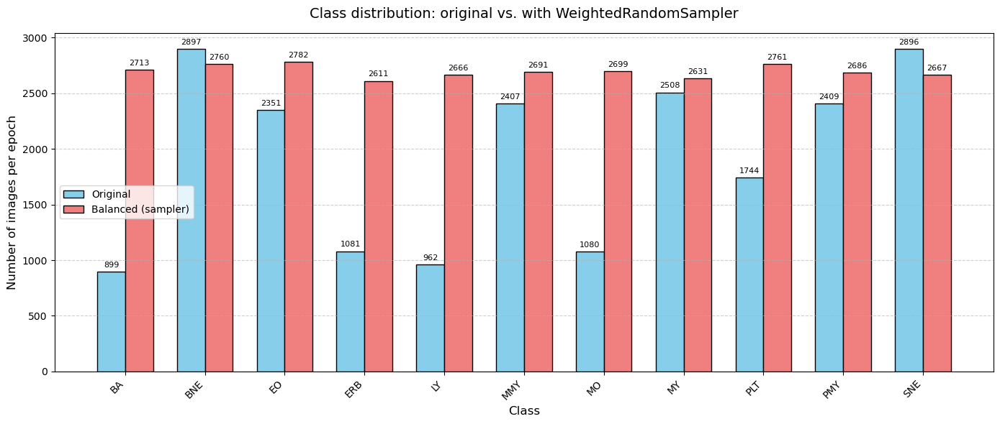


Original distribution: {'BA': np.int64(899), 'BNE': np.int64(2897), 'EO': np.int64(2351), 'ERB': np.int64(1081), 'LY': np.int64(962), 'MMY': np.int64(2407), 'MO': np.int64(1080), 'MY': np.int64(2508), 'PLT': np.int64(1744), 'PMY': np.int64(2409), 'SNE': np.int64(2896)}
Balanced distribution (sample of 29667 images): {'BA': np.int64(2713), 'BNE': np.int64(2760), 'EO': np.int64(2782), 'ERB': np.int64(2611), 'LY': np.int64(2666), 'MMY': np.int64(2691), 'MO': np.int64(2699), 'MY': np.int64(2631), 'PLT': np.int64(2761), 'PMY': np.int64(2686), 'SNE': np.int64(2667)}


In [13]:
# =============================================================
# CLASS BALANCING VISUALIZATION
# =============================================================
import matplotlib.pyplot as plt

# Original distribution (without sampler)
original_counts = class_counts
class_names = train_dataset.classes

# Simulate one epoch with the sampler to obtain the balanced distribution
sampler_indices = list(sampler)
sampled_labels = [train_labels[i] for i in sampler_indices]
balanced_counts = np.bincount(sampled_labels, minlength=NUM_CLASSES)

# Comparative bar chart
x = np.arange(NUM_CLASSES)          # class positions
width = 0.35                         # bar width

fig, ax = plt.subplots(figsize=(14, 6))
bars1 = ax.bar(x - width/2, original_counts, width, label='Original', color='skyblue', edgecolor='black')
bars2 = ax.bar(x + width/2, balanced_counts, width, label='Balanced (sampler)', color='lightcoral', edgecolor='black')

ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Number of images per epoch', fontsize=12)
ax.set_title('Class distribution: original vs. with WeightedRandomSampler', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Add values on top of bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

print(f"\nOriginal distribution: {dict(zip(class_names, original_counts))}")
print(f"Balanced distribution (sample of {num_samples} images): {dict(zip(class_names, balanced_counts))}")


In [14]:
# =============================================================
# OPTIMIZER EXECUTION LOOP — NATURALIZE 2K-PBC
# =============================================================
import os, torch, random
import numpy as np


OPTIMIZERS_TO_RUN = ["Adam", "AdamW", "RAdam", "AdaHarmon", "RMSprop", "SGD", "AdaBelief", "Lion", "AMSGrad", "Adamax"]

all_results   = {}
all_histories = {}

for opt_name in OPTIMIZERS_TO_RUN:
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    np.random.seed(42)
    random.seed(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

    print(f"\n" + "="*60)
    print(f"  EXECUTING EXPERIMENT: {opt_name}")
    print("="*60)


    model = EfficientNetV2(num_classes=NUM_CLASSES)

    results, history = train_and_evaluate_model(
        model             = model,
        optimizer_name    = opt_name,
        hparams           = HYPERPARAMS[opt_name],
        train_loader      = train_loader,
        train_eval_loader = train_eval_loader,
        val_loader        = val_loader,
        test_loader       = test_loader,
        train_dataset     = train_dataset,
        val_dataset       = val_dataset,
        test_dataset      = test_dataset,
        NUM_EPOCHS        = NUM_EPOCHS,
        NUM_CLASSES       = NUM_CLASSES,
        device            = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    )


    all_results[opt_name]   = results
    all_histories[opt_name] = history

# Summary table
print("\n" + "="*110)
print(f"{'FINAL COMPARATIVE PERFORMANCE SUMMARY — NATURALIZE 2K-PBC':^110}")
print("="*110)
print(f"{'Optimizer':<20} | {'Trn Acc (%)':<11} | {'Trn Loss':<10} | "
      f"{'Val Acc (%)':<11} | {'Val Loss':<10} | {'Test Acc (%)':<12} | {'Test Loss':<10}")
print("-" * 110)

sorted_results = sorted(all_results.items(),
                        key=lambda x: x[1]['test_accuracy'], reverse=True)

for opt_name, res in sorted_results:
    h        = all_histories[opt_name]
    trn_acc  = h['train_acc'][-1]  * 100
    trn_loss = h['train_loss'][-1]
    val_acc  = h['val_acc'][-1]    * 100
    val_loss = h['val_loss'][-1]
    tst_acc  = res['test_accuracy'] * 100
    tst_loss = res['test_loss']
    top      = " [TOP]" if opt_name == sorted_results[0][0] else ""
    print(f"{opt_name:<20} | {trn_acc:<11.2f} | {trn_loss:<10.4f} | "
          f"{val_acc:<11.2f} | {val_loss:<10.4f} | {tst_acc:<12.2f} | {tst_loss:<10.4f}{top}")

print("-" * 110)




  EXECUTING EXPERIMENT: Adam
Epoch 1/80 -> Trn Loss: 1.8301, Trn Acc: 0.2633 | Val Loss: 1.7983, Val Acc: 0.2828, Val AUC: 0.8574 ✓ best
Epoch 2/80 -> Trn Loss: 1.2233, Trn Acc: 0.4724 | Val Loss: 1.1861, Val Acc: 0.4855, Val AUC: 0.9397 ✓ best
Epoch 3/80 -> Trn Loss: 1.6174, Trn Acc: 0.4242 | Val Loss: 1.5985, Val Acc: 0.4404, Val AUC: 0.9114
Epoch 4/80 -> Trn Loss: 2.0515, Trn Acc: 0.3990 | Val Loss: 2.0347, Val Acc: 0.4036, Val AUC: 0.8948
Epoch 5/80 -> Trn Loss: 1.1672, Trn Acc: 0.5229 | Val Loss: 1.1457, Val Acc: 0.5236, Val AUC: 0.9387 ✓ best
Epoch 6/80 -> Trn Loss: 1.1021, Trn Acc: 0.5906 | Val Loss: 1.0834, Val Acc: 0.5944, Val AUC: 0.9560 ✓ best
Epoch 7/80 -> Trn Loss: 0.9388, Trn Acc: 0.6311 | Val Loss: 0.9297, Val Acc: 0.6390, Val AUC: 0.9606 ✓ best
Epoch 8/80 -> Trn Loss: 0.6555, Trn Acc: 0.7312 | Val Loss: 0.6452, Val Acc: 0.7283, Val AUC: 0.9789 ✓ best
Epoch 9/80 -> Trn Loss: 0.9899, Trn Acc: 0.6454 | Val Loss: 0.9685, Val Acc: 0.6580, Val AUC: 0.9657
Epoch 10/80 -> Trn




  EXECUTING EXPERIMENT: AdamW
Epoch 1/80 -> Trn Loss: 1.8374, Trn Acc: 0.2693 | Val Loss: 1.5791, Val Acc: 0.3506, Val AUC: 0.8521 ✓ best
Epoch 2/80 -> Trn Loss: 1.5260, Trn Acc: 0.3703 | Val Loss: 1.5376, Val Acc: 0.4074, Val AUC: 0.9374 ✓ best
Epoch 3/80 -> Trn Loss: 1.4114, Trn Acc: 0.4515 | Val Loss: 1.5885, Val Acc: 0.4393, Val AUC: 0.9196 ✓ best
Epoch 4/80 -> Trn Loss: 1.8154, Trn Acc: 0.4029 | Val Loss: 1.5869, Val Acc: 0.4495, Val AUC: 0.9032 ✓ best
Epoch 5/80 -> Trn Loss: 1.6146, Trn Acc: 0.4594 | Val Loss: 1.3972, Val Acc: 0.5102, Val AUC: 0.9384 ✓ best
Epoch 6/80 -> Trn Loss: 1.1402, Trn Acc: 0.5591 | Val Loss: 1.0658, Val Acc: 0.5863, Val AUC: 0.9476 ✓ best
Epoch 7/80 -> Trn Loss: 1.0270, Trn Acc: 0.6044 | Val Loss: 0.8884, Val Acc: 0.6519, Val AUC: 0.9623 ✓ best
Epoch 8/80 -> Trn Loss: 0.8122, Trn Acc: 0.6807 | Val Loss: 0.8469, Val Acc: 0.6661, Val AUC: 0.9775 ✓ best
Epoch 9/80 -> Trn Loss: 0.8264, Trn Acc: 0.6886 | Val Loss: 0.7893, Val Acc: 0.6906, Val AUC: 0.9736 ✓ 




  EXECUTING EXPERIMENT: RAdam
Epoch 1/80 -> Trn Loss: 1.9304, Trn Acc: 0.2450 | Val Loss: 1.9205, Val Acc: 0.2424, Val AUC: 0.8433 ✓ best
Epoch 2/80 -> Trn Loss: 1.2967, Trn Acc: 0.4503 | Val Loss: 1.2864, Val Acc: 0.4487, Val AUC: 0.9279 ✓ best
Epoch 3/80 -> Trn Loss: 1.6439, Trn Acc: 0.3943 | Val Loss: 1.6697, Val Acc: 0.4029, Val AUC: 0.9170
Epoch 4/80 -> Trn Loss: 2.0950, Trn Acc: 0.3843 | Val Loss: 2.1260, Val Acc: 0.3795, Val AUC: 0.8926
Epoch 5/80 -> Trn Loss: 1.2104, Trn Acc: 0.5094 | Val Loss: 1.2050, Val Acc: 0.4941, Val AUC: 0.9353 ✓ best
Epoch 6/80 -> Trn Loss: 1.1209, Trn Acc: 0.5812 | Val Loss: 1.1197, Val Acc: 0.5782, Val AUC: 0.9494 ✓ best
Epoch 7/80 -> Trn Loss: 0.9489, Trn Acc: 0.6215 | Val Loss: 0.9436, Val Acc: 0.6202, Val AUC: 0.9654 ✓ best
Epoch 8/80 -> Trn Loss: 0.6613, Trn Acc: 0.7275 | Val Loss: 0.6686, Val Acc: 0.7300, Val AUC: 0.9751 ✓ best
Epoch 9/80 -> Trn Loss: 1.0029, Trn Acc: 0.6464 | Val Loss: 0.9690, Val Acc: 0.6387, Val AUC: 0.9671
Epoch 10/80 -> T




  EXECUTING EXPERIMENT: AdaHarmon
Epoch 1/80 -> Trn Loss: 2.4858, Trn Acc: 0.1000 | Val Loss: 2.4876, Val Acc: 0.1000, Val AUC: 0.4029 ✓ best
Epoch 2/80 -> Trn Loss: 2.4978, Trn Acc: 0.2025 | Val Loss: 2.4758, Val Acc: 0.1994, Val AUC: 0.7764 ✓ best
Epoch 3/80 -> Trn Loss: 1.8411, Trn Acc: 0.4017 | Val Loss: 1.8271, Val Acc: 0.3820, Val AUC: 0.8833 ✓ best
Epoch 4/80 -> Trn Loss: 1.4441, Trn Acc: 0.4601 | Val Loss: 1.4383, Val Acc: 0.4467, Val AUC: 0.9190 ✓ best
Epoch 5/80 -> Trn Loss: 1.5105, Trn Acc: 0.5106 | Val Loss: 1.4711, Val Acc: 0.5070, Val AUC: 0.9140 ✓ best
Epoch 6/80 -> Trn Loss: 1.2402, Trn Acc: 0.5255 | Val Loss: 1.1982, Val Acc: 0.5183, Val AUC: 0.9461 ✓ best
Epoch 7/80 -> Trn Loss: 0.9680, Trn Acc: 0.6135 | Val Loss: 0.9618, Val Acc: 0.6226, Val AUC: 0.9552 ✓ best
Epoch 8/80 -> Trn Loss: 0.6548, Trn Acc: 0.7393 | Val Loss: 0.6475, Val Acc: 0.7353, Val AUC: 0.9800 ✓ best
Epoch 9/80 -> Trn Loss: 0.9832, Trn Acc: 0.6551 | Val Loss: 0.9511, Val Acc: 0.6624, Val AUC: 0.966




  EXECUTING EXPERIMENT: RMSprop
Epoch 1/80 -> Trn Loss: 3.1523, Trn Acc: 0.1000 | Val Loss: 3.1410, Val Acc: 0.1000, Val AUC: 0.6648 ✓ best
Epoch 2/80 -> Trn Loss: 2.2175, Trn Acc: 0.2684 | Val Loss: 2.2207, Val Acc: 0.2692, Val AUC: 0.8580 ✓ best
Epoch 3/80 -> Trn Loss: 1.3015, Trn Acc: 0.4688 | Val Loss: 1.2835, Val Acc: 0.4680, Val AUC: 0.9296 ✓ best
Epoch 4/80 -> Trn Loss: 2.0380, Trn Acc: 0.3448 | Val Loss: 2.0143, Val Acc: 0.3595, Val AUC: 0.8926
Epoch 5/80 -> Trn Loss: 1.6060, Trn Acc: 0.4749 | Val Loss: 1.6127, Val Acc: 0.4812, Val AUC: 0.9083 ✓ best
Epoch 6/80 -> Trn Loss: 0.9921, Trn Acc: 0.5743 | Val Loss: 0.9655, Val Acc: 0.5726, Val AUC: 0.9502 ✓ best
Epoch 7/80 -> Trn Loss: 1.0477, Trn Acc: 0.6101 | Val Loss: 1.0262, Val Acc: 0.6098, Val AUC: 0.9522 ✓ best
Epoch 8/80 -> Trn Loss: 0.8441, Trn Acc: 0.6669 | Val Loss: 0.8234, Val Acc: 0.6630, Val AUC: 0.9754 ✓ best
Epoch 9/80 -> Trn Loss: 0.9480, Trn Acc: 0.6491 | Val Loss: 0.9509, Val Acc: 0.6447, Val AUC: 0.9601
Epoch 1




  EXECUTING EXPERIMENT: SGD
Epoch 1/80 -> Trn Loss: 2.4037, Trn Acc: 0.1649 | Val Loss: 2.3868, Val Acc: 0.1616, Val AUC: 0.7607 ✓ best
Epoch 2/80 -> Trn Loss: 1.3377, Trn Acc: 0.4747 | Val Loss: 1.2977, Val Acc: 0.4694, Val AUC: 0.9264 ✓ best
Epoch 3/80 -> Trn Loss: 2.0828, Trn Acc: 0.3134 | Val Loss: 2.1078, Val Acc: 0.3153, Val AUC: 0.8712
Epoch 4/80 -> Trn Loss: 1.7627, Trn Acc: 0.4549 | Val Loss: 1.7596, Val Acc: 0.4447, Val AUC: 0.9061
Epoch 5/80 -> Trn Loss: 1.3290, Trn Acc: 0.5167 | Val Loss: 1.3450, Val Acc: 0.5214, Val AUC: 0.9284 ✓ best
Epoch 6/80 -> Trn Loss: 1.2314, Trn Acc: 0.5365 | Val Loss: 1.2090, Val Acc: 0.5437, Val AUC: 0.9448 ✓ best
Epoch 7/80 -> Trn Loss: 1.0293, Trn Acc: 0.6360 | Val Loss: 1.0187, Val Acc: 0.6284, Val AUC: 0.9589 ✓ best
Epoch 8/80 -> Trn Loss: 0.7277, Trn Acc: 0.7188 | Val Loss: 0.7158, Val Acc: 0.7227, Val AUC: 0.9836 ✓ best
Epoch 9/80 -> Trn Loss: 0.6355, Trn Acc: 0.7582 | Val Loss: 0.6016, Val Acc: 0.7552, Val AUC: 0.9772 ✓ best
Epoch 10/80




  EXECUTING EXPERIMENT: AdaBelief
Epoch 1/80 -> Trn Loss: 1.8331, Trn Acc: 0.2657 | Val Loss: 1.7051, Val Acc: 0.3191, Val AUC: 0.8552 ✓ best
Epoch 2/80 -> Trn Loss: 1.3453, Trn Acc: 0.4312 | Val Loss: 1.3199, Val Acc: 0.4667, Val AUC: 0.9388 ✓ best
Epoch 3/80 -> Trn Loss: 1.5344, Trn Acc: 0.4352 | Val Loss: 1.5875, Val Acc: 0.4514, Val AUC: 0.9147
Epoch 4/80 -> Trn Loss: 1.9564, Trn Acc: 0.4006 | Val Loss: 1.8544, Val Acc: 0.4313, Val AUC: 0.8982
Epoch 5/80 -> Trn Loss: 1.3478, Trn Acc: 0.4973 | Val Loss: 1.2483, Val Acc: 0.5291, Val AUC: 0.9385 ✓ best
Epoch 6/80 -> Trn Loss: 1.1178, Trn Acc: 0.5779 | Val Loss: 1.0712, Val Acc: 0.6031, Val AUC: 0.9526 ✓ best
Epoch 7/80 -> Trn Loss: 0.9749, Trn Acc: 0.6204 | Val Loss: 0.9178, Val Acc: 0.6581, Val AUC: 0.9613 ✓ best
Epoch 8/80 -> Trn Loss: 0.7194, Trn Acc: 0.7108 | Val Loss: 0.7259, Val Acc: 0.7150, Val AUC: 0.9783 ✓ best
Epoch 9/80 -> Trn Loss: 0.9249, Trn Acc: 0.6628 | Val Loss: 0.8890, Val Acc: 0.6840, Val AUC: 0.9688
Epoch 10/80 




  EXECUTING EXPERIMENT: Lion
Epoch 1/80 -> Trn Loss: 1.8336, Trn Acc: 0.2662 | Val Loss: 1.6957, Val Acc: 0.3178, Val AUC: 0.8548 ✓ best
Epoch 2/80 -> Trn Loss: 1.3688, Trn Acc: 0.4233 | Val Loss: 1.3640, Val Acc: 0.4584, Val AUC: 0.9386 ✓ best
Epoch 3/80 -> Trn Loss: 1.5184, Trn Acc: 0.4373 | Val Loss: 1.5864, Val Acc: 0.4284, Val AUC: 0.9153
Epoch 4/80 -> Trn Loss: 1.9381, Trn Acc: 0.4009 | Val Loss: 1.8183, Val Acc: 0.4261, Val AUC: 0.8988
Epoch 5/80 -> Trn Loss: 1.3825, Trn Acc: 0.4924 | Val Loss: 1.2743, Val Acc: 0.4998, Val AUC: 0.9385 ✓ best
Epoch 6/80 -> Trn Loss: 1.1208, Trn Acc: 0.5755 | Val Loss: 1.0900, Val Acc: 0.6184, Val AUC: 0.9519 ✓ best
Epoch 7/80 -> Trn Loss: 0.9817, Trn Acc: 0.6183 | Val Loss: 0.9218, Val Acc: 0.6144, Val AUC: 0.9614
Epoch 8/80 -> Trn Loss: 0.7315, Trn Acc: 0.7069 | Val Loss: 0.7624, Val Acc: 0.6750, Val AUC: 0.9782 ✓ best
Epoch 9/80 -> Trn Loss: 0.9122, Trn Acc: 0.6662 | Val Loss: 0.8862, Val Acc: 0.6863, Val AUC: 0.9694 ✓ best
Epoch 10/80 -> Tr




  EXECUTING EXPERIMENT: AMSGrad
Epoch 1/80 -> Trn Loss: 1.8329, Trn Acc: 0.2656 | Val Loss: 1.7098, Val Acc: 0.3065, Val AUC: 0.8553 ✓ best
Epoch 2/80 -> Trn Loss: 1.3397, Trn Acc: 0.4331 | Val Loss: 1.3262, Val Acc: 0.4567, Val AUC: 0.9388 ✓ best
Epoch 3/80 -> Trn Loss: 1.5382, Trn Acc: 0.4347 | Val Loss: 1.5924, Val Acc: 0.4409, Val AUC: 0.9145
Epoch 4/80 -> Trn Loss: 1.9608, Trn Acc: 0.4005 | Val Loss: 1.8561, Val Acc: 0.4203, Val AUC: 0.8980
Epoch 5/80 -> Trn Loss: 1.3395, Trn Acc: 0.4985 | Val Loss: 1.2328, Val Acc: 0.5227, Val AUC: 0.9385 ✓ best
Epoch 6/80 -> Trn Loss: 1.1171, Trn Acc: 0.5785 | Val Loss: 1.0746, Val Acc: 0.5875, Val AUC: 0.9527 ✓ best
Epoch 7/80 -> Trn Loss: 0.9732, Trn Acc: 0.6209 | Val Loss: 0.9276, Val Acc: 0.6391, Val AUC: 0.9612 ✓ best
Epoch 8/80 -> Trn Loss: 0.7164, Trn Acc: 0.7118 | Val Loss: 0.7220, Val Acc: 0.7120, Val AUC: 0.9783 ✓ best
Epoch 9/80 -> Trn Loss: 0.9278, Trn Acc: 0.6620 | Val Loss: 0.9002, Val Acc: 0.6697, Val AUC: 0.9687
Epoch 10/80 ->




  EXECUTING EXPERIMENT: Adamax
Epoch 1/80 -> Trn Loss: 1.8328, Trn Acc: 0.2655 | Val Loss: 1.7169, Val Acc: 0.2994, Val AUC: 0.8554 ✓ best
Epoch 2/80 -> Trn Loss: 1.3335, Trn Acc: 0.4352 | Val Loss: 1.3127, Val Acc: 0.4547, Val AUC: 0.9389 ✓ best
Epoch 3/80 -> Trn Loss: 1.5424, Trn Acc: 0.4341 | Val Loss: 1.5905, Val Acc: 0.4406, Val AUC: 0.9144
Epoch 4/80 -> Trn Loss: 1.9656, Trn Acc: 0.4004 | Val Loss: 1.8645, Val Acc: 0.4199, Val AUC: 0.8979
Epoch 5/80 -> Trn Loss: 1.3303, Trn Acc: 0.4998 | Val Loss: 1.2427, Val Acc: 0.5168, Val AUC: 0.9386 ✓ best
Epoch 6/80 -> Trn Loss: 1.1163, Trn Acc: 0.5791 | Val Loss: 1.0801, Val Acc: 0.5933, Val AUC: 0.9529 ✓ best
Epoch 7/80 -> Trn Loss: 0.9714, Trn Acc: 0.6214 | Val Loss: 0.9106, Val Acc: 0.6486, Val AUC: 0.9612 ✓ best
Epoch 8/80 -> Trn Loss: 0.7132, Trn Acc: 0.7128 | Val Loss: 0.7078, Val Acc: 0.7059, Val AUC: 0.9783 ✓ best
Epoch 9/80 -> Trn Loss: 0.9313, Trn Acc: 0.6611 | Val Loss: 0.8977, Val Acc: 0.6707, Val AUC: 0.9685
Epoch 10/80 -> 



                          FINAL COMPARATIVE PERFORMANCE SUMMARY — NATURALIZE 2K-PBC                           
Optimizer            | Trn Acc (%) | Trn Loss   | Val Acc (%) | Val Loss   | Test Acc (%) | Test Loss 
--------------------------------------------------------------------------------------------------------------
Lion                 | 94.98       | 0.2418     | 92.98       | 0.3224     | 93.52        | 0.3107     [TOP]
AdaBelief            | 95.06       | 0.2418     | 93.06       | 0.3223     | 93.47        | 0.3132    
Adamax               | 94.75       | 0.2406     | 92.75       | 0.3208     | 93.34        | 0.3268    
AdaHarmon            | 94.52       | 0.1482     | 93.08       | 0.1711     | 93.21        | 0.1965    
AdamW                | 94.65       | 0.1550     | 92.54       | 0.1791     | 92.98        | 0.1956    
SGD                  | 94.14       | 0.1399     | 92.50       | 0.1809     | 92.98        | 0.2135    
RAdam                | 94.34       | 0.1525     |

In [15]:
# =============================================================
# FINAL REPORT AND VISUALIZATION — NATURALIZE 2K-PBC
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import random
import torch
import os
from scipy.ndimage import gaussian_filter1d
from sklearn.metrics import recall_score, f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from matplotlib.colors import LinearSegmentedColormap, to_rgb

sns.set_theme(style="whitegrid", font="Verdana")
plt.rcParams["font.family"] = "Verdana"

# -------------------------------------------------------------------
_sample_model = EfficientNetV2(num_classes=NUM_CLASSES)
NUM_PARAMS_BACKBONE = sum(p.numel() for p in _sample_model.parameters() if p.requires_grad)
print(f"✓ Trainable parameters: {NUM_PARAMS_BACKBONE:,}")
del _sample_model

OPT_COLORS_NICE = {'SGD': '#C62828', 'Adam': '#6B8E23', 'AdamW': '#56B4E9', 'RAdam': '#009E73', 'AdaHarmon': '#212121', 'RMSprop': '#F57F17', 'AdaBelief': '#8E24AA', 'Lion': '#E91E63', 'AMSGrad': '#00ACC1', 'Adamax': '#795548'}

# 11 classes (Naturalize 2K‑PBC)
CATEGORIES = [
    'Basophil',          # BA
    'Banded Neutrophil', # BNE
    'Eosinophil',        # EO
    'Erythroblast',      # ERB
    'Lymphocyte',        # LY
    'Meta-myelocyte',    # MMY
    'Monocyte',          # MO
    'Myelocyte',         # MY
    'Platelet',          # PLT
    'Pro-myelocyte',     # PMY
    'Segmented Neutrophil' # SNE
]

# -------------------------------------------------------------------
# 1. Learning curves – both Raw and Smoothed versions
# -------------------------------------------------------------------

# Reconcile test metrics directly from the stored prediction arrays (macro definitions).
from sklearn.metrics import accuracy_score, f1_score, recall_score
for _name, _res in all_results.items():
    _yt = np.asarray(_res["y_true"], dtype=int)
    _yp = np.asarray(_res["y_pred"], dtype=int)
    _ys = np.asarray(_res["y_scores"], dtype=float)
    _classes = list(range(_ys.shape[1]))
    _ybin = label_binarize(_yt, classes=_classes)
    _res["test_accuracy"] = float(accuracy_score(_yt, _yp))
    _res["test_auc"] = float(roc_auc_score(_ybin, _ys, average="macro", multi_class="ovr"))
    _res["f1_score"] = float(f1_score(_yt, _yp, average="macro", zero_division=0))
    _res["recall"] = float(recall_score(_yt, _yp, average="macro", zero_division=0))

if len(CATEGORIES) != 5:
    _dataset_label = "Naturalize 2K-PBC" if len(CATEGORIES) == 11 else "PBC BloodMNIST"
    print("\n" + "=" * 110)
    print(f"EXPERIMENTAL RESULTS SUMMARY — {_dataset_label} (TEST SET)")
    print("=" * 110)
    print(f"{'Optimizer':<20} | {'Acc (%)':<9} | {'Loss':<8} | {'AUC':<8} | {'F1-Score':<8} | {'Recall':<8} | {'Time(s)':<9} | Params")
    print("-" * 110)
    for _name, _res in sorted(all_results.items(), key=lambda _x: _x[1]["test_accuracy"], reverse=True):
        print(f"{_name:<20} | {_res['test_accuracy']*100:<9.2f} | {_res['test_loss']:<8.4f} | {_res['test_auc']:<8.4f} | {_res['f1_score']:<8.4f} | {_res['recall']:<8.4f} | {_res['training_time']:<9.1f} | {_res['params']:,}")
    print("-" * 110)

def plot_benchmark_curves(results, histories, save_dir):
    versions = ['Raw', 'Smoothed']
    for version in versions:
        fig, axes = plt.subplots(2, 2, figsize=(20, 14))

        # ---- Compute dynamic limits for Loss (only train and val) ----
        max_loss_full = 0.0
        min_loss_zoom = float('inf')
        max_loss_zoom = 0.0

        for opt_name in results.keys():
            h = histories[opt_name]
            train_loss = np.array(h['train_loss'])
            val_loss = np.array(h['val_loss'])

            # Apply smoothing only for the Smoothed version when computing limits
            if version == 'Smoothed':
                train_loss_smooth = gaussian_filter1d(train_loss, sigma=0.8)
                val_loss_smooth = gaussian_filter1d(val_loss, sigma=0.8)
                all_loss = list(train_loss_smooth) + list(val_loss_smooth)
            else:
                all_loss = list(train_loss) + list(val_loss)

            if all_loss:
                max_loss_full = max(max_loss_full, max(all_loss))

            # Zoom: last 20 epochs (or all if fewer)
            zoom_epochs = min(20, len(train_loss))
            if version == 'Smoothed':
                recent_train = train_loss_smooth[-zoom_epochs:] if zoom_epochs > 0 else []
                recent_val   = val_loss_smooth[-zoom_epochs:]   if zoom_epochs > 0 else []
            else:
                recent_train = train_loss[-zoom_epochs:] if zoom_epochs > 0 else []
                recent_val   = val_loss[-zoom_epochs:]   if zoom_epochs > 0 else []

            recent_loss = list(recent_train) + list(recent_val)
            if recent_loss:
                min_loss_zoom = min(min_loss_zoom, min(recent_loss))
                max_loss_zoom = max(max_loss_zoom, max(recent_loss))

        margin_full = 0.05 * max_loss_full if max_loss_full > 0 else 0.1
        margin_zoom = 0.05 * (max_loss_zoom - min_loss_zoom) if (max_loss_zoom - min_loss_zoom) > 0 else 0.05
        loss_full_ylim = (0, max_loss_full + margin_full)
        loss_zoom_ylim = (min_loss_zoom - margin_zoom, max_loss_zoom + margin_zoom)

        # Metrics: loss and accuracy
        metrics = [
            ('loss', axes[0, 0], axes[1, 0], 'Loss', loss_full_ylim, loss_zoom_ylim),
            ('acc',  axes[0, 1], axes[1, 1], 'Accuracy', (0, 1.01), (0.85, 1.005))
        ]

        # Draw SGD last so it appears on top
        optimizers = sorted(results.keys(), key=lambda x: x != "SGD")

        for m_key, ax_full, ax_zoom, label, full_lim, zoom_lim in metrics:
            for opt_name in optimizers:
                h = histories[opt_name]
                color = OPT_COLORS_NICE.get(opt_name, "#000000")

                t_data = np.array(h[f'train_{m_key}'])
                v_data = np.array(h[f'val_{m_key}'])
                if version == 'Smoothed':
                    t_data = gaussian_filter1d(t_data, sigma=0.8)
                    v_data = gaussian_filter1d(v_data, sigma=0.8)

                epochs = range(1, len(t_data) + 1)

                for ax in [ax_full, ax_zoom]:
                    ax.plot(epochs, t_data, label=f"{opt_name} (Train)", color=color, linewidth=2.5)
                    ax.plot(epochs, v_data, label=f"{opt_name} (Val)",   color=color, linestyle='--', linewidth=1.8, alpha=0.7)
                    # Emphasize SGD with markers at the end
                    if opt_name == "SGD":
                        ax.scatter(epochs[-1], t_data[-1], color=color, s=60, zorder=5, edgecolors='white')
                        ax.scatter(epochs[-1], v_data[-1], color=color, s=60, zorder=5, marker='s', edgecolors='white')
                        # Slightly thicker line
                        ax.plot(epochs, t_data, color=color, linewidth=3.0, alpha=0.9)
                        ax.plot(epochs, v_data, color=color, linestyle='--', linewidth=2.5, alpha=0.9)

            # Configure subplots
            for ax, title_suffix, ylim in [(ax_full, 'Full View', full_lim), (ax_zoom, 'Zoomed View', zoom_lim)]:
                ax.set_title(f"Learning Behavior: {label} ({title_suffix})", fontsize=15, fontweight='bold')
                ax.set_xlabel('Epoch')
                ax.set_ylabel(label)
                ax.set_ylim(ylim)
                ax.set_xlim(1, len(epochs))
                ax.legend(fontsize=9, ncol=2)
                ax.grid(True, linestyle='--', alpha=0.5)

        plt.suptitle(f'Performance — Naturalize 2K-PBC Dataset | EfficientNetV2 From Scratch ({version} Data)',
                     fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/learning_curves_{version.lower()}_naturalize_96x96_env2.png', dpi=600, bbox_inches='tight')
        plt.show()

# -------------------------------------------------------------------
# 2. ROC Curves (full and zoom)
# -------------------------------------------------------------------
def plot_benchmark_roc(results, save_dir):
    n_opts = len(results)
    fig, axes = plt.subplots(2, n_opts, figsize=(6 * n_opts, 12), squeeze=False)
    y_bins = {}
    for col, (opt_name, res) in enumerate(results.items()):
        y_true = np.asarray(res['y_true'])
        y_scores = np.asarray(res['y_scores'])
        if opt_name not in y_bins:
            y_bins[opt_name] = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
        y_bin = y_bins[opt_name]
        opt_color = OPT_COLORS_NICE.get(opt_name, '#000000')
        macro_auc = roc_auc_score(y_bin, y_scores, average='macro')
        for row, (ax, zoom) in enumerate(((axes[0, col], False), (axes[1, col], True))):
            for class_idx in range(NUM_CLASSES):
                fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_scores[:, class_idx])
                class_color = plt.get_cmap('tab20')(class_idx % 20)
                class_auc = auc(fpr, tpr)
                ax.plot(fpr, tpr, color=class_color, linewidth=1.7,
                        label=f"{CATEGORIES[class_idx]} (AUC={class_auc:.3f})")
            ax.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.3, linewidth=1)
            ax.set_xlabel('False Positive Rate')
            ax.set_ylabel('True Positive Rate')
            ax.legend(fontsize=5.5, loc='lower right')
            if zoom:
                if NUM_CLASSES >= 10:
                    xlim, ylim = (-0.002, 0.05), (0.95, 1.002)
                else:
                    xlim, ylim = (-0.002, 0.1), (0.90, 1.002)
                ax.set_xlim(*xlim); ax.set_ylim(*ylim)
                ax.set_title(f"ROC Zoom: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
                ax.grid(True, linestyle='--', alpha=0.5)
                from matplotlib.patches import Rectangle
                axes[0, col].add_patch(Rectangle((xlim[0], ylim[0]), xlim[1]-xlim[0], ylim[1]-ylim[0],
                    linewidth=1.5, edgecolor='gray', facecolor='none', linestyle='--'))
            else:
                ax.set_title(f"ROC: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
    plt.suptitle('ROC Curves — Naturalize 2K-PBC Dataset | Full view (top) & Zoomed (bottom)',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f'{save_dir}/roc_curves_naturalize2k_env2.png', dpi=200, bbox_inches='tight')
    plt.show()

def mix_with_white(color, amount):
    rgb=to_rgb(color); white=(1.,1.,1.)
    return tuple(rgb[i]+(white[i]-rgb[i])*amount for i in range(3))

def plot_benchmark_cm(results, save_dir, light_amount=0.9, dark_factor=0.7):
    n=len(results); cols=2; rows=math.ceil(n/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(16,7*rows+0.5*(rows-1))); axes=axes.flatten()
    for i,(opt_name,res) in enumerate(results.items()):
        cm=confusion_matrix(res['y_true'],res['y_pred']); color=OPT_COLORS_NICE.get(opt_name,'#000000')
        light=mix_with_white(color,light_amount); rgb=to_rgb(color)
        dark=tuple(c*dark_factor for c in rgb) if dark_factor<1 else color
        cmap=LinearSegmentedColormap.from_list(f'cmap_{opt_name}',[light,dark],N=256)
        sns.heatmap(cm,annot=True,fmt='d',cmap=cmap,ax=axes[i],xticklabels=CATEGORIES,yticklabels=CATEGORIES,cbar=True,square=True,annot_kws={'size':8})
        axes[i].set_title(f'Confusion Matrix: {opt_name}',fontweight='bold',color=color); axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('True')
        axes[i].set_xticklabels(axes[i].get_xticklabels(),rotation=45,ha='right')
    for j in range(n,len(axes)): fig.delaxes(axes[j])
    plt.tight_layout(); plt.subplots_adjust(wspace=.25,hspace=.25)
    plt.savefig(f'{save_dir}/confusion_matrices_naturalize_96x96_env2.png',dpi=300,bbox_inches='tight'); plt.show()



✓ Trainable parameters: 20,191,579

EXPERIMENTAL RESULTS SUMMARY — Naturalize 2K-PBC (TEST SET)
Optimizer            | Acc (%)   | Loss     | AUC      | F1-Score | Recall   | Time(s)   | Params
--------------------------------------------------------------------------------------------------------------
Lion                 | 93.52     | 0.3107   | 0.9924   | 0.9218   | 0.9298   | 13632.4   | 20,191,579
AdaBelief            | 93.47     | 0.3132   | 0.9926   | 0.9226   | 0.9303   | 14263.7   | 20,191,579
Adamax               | 93.34     | 0.3268   | 0.9928   | 0.9200   | 0.9275   | 13210.4   | 20,191,579
AdaHarmon            | 93.21     | 0.1965   | 0.9974   | 0.9328   | 0.9329   | 15503.3   | 20,191,579
AdamW                | 92.98     | 0.1956   | 0.9942   | 0.9319   | 0.9348   | 9775.7    | 20,191,579
SGD                  | 92.98     | 0.2135   | 0.9974   | 0.9338   | 0.9331   | 9213.3    | 20,191,579
RAdam                | 92.83     | 0.2099   | 0.9941   | 0.9301   | 0.9328   | 9498